# MSC 7103 Machine Learning: Practical Exam Project
## A Machine Learning and Spatial Data Approach for Predicting Priority Areas for New Rural Water Points in Uganda

| | |
|---|---|
| **Student** | Fredrick Tamale (Reg. No. 2026/HD05/22751U, Student No. 2600722751) |
| **Programme** | MSc Computer Science, Makerere University |
| **Case organisation** | WaterAid Uganda |
| **Data** | Water Point Data Exchange - Plus (WPdx+), Uganda extract |

**Problem.** Many rural water points in Uganda serve far more people than they were designed for. Planners need to know
*where* new water points are most needed. This notebook builds a model that classifies each rural water point's
surroundings as **low, medium or high priority** for an additional water point, explains what drives that, and turns the
results into a sub-county priority map.

**Notebook outline (follows the exam requirements)**
1. Setup
2. Problem definition and dataset
3. Data preprocessing and exploration
4. Spatial feature engineering
5. Model development (logistic regression, random forest, XGBoost)
6. Model evaluation and comparison
7. Interpretation of results (feature importance, SHAP, ablation, regional performance)
8. Priority map of sub-counties
9. Summary of results

## 1. Setup

In [1]:
# Installs any missing packages automatically so the notebook also runs on a fresh machine.
import importlib.util, subprocess, sys
REQUIRED = {'xgboost': 'xgboost', 'shap': 'shap', 'sklearn': 'scikit-learn', 'seaborn': 'seaborn',
            'folium': 'folium', 'scipy': 'scipy'}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print('Installing missing packages:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
else:
    print('All required packages are available.')

All required packages are available.


In [2]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

from sklearn.base import clone
from sklearn.neighbors import BallTree
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
import shap
import folium

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
FIG, OUTD = 'figures', 'outputs'
os.makedirs(FIG, exist_ok=True); os.makedirs(OUTD, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
CLASSES = ['Low', 'Medium', 'High']
PAL = {'Low': '#2E7D32', 'Medium': '#F9A825', 'High': '#C62828'}
RESULTS = {}

## 2. Problem definition and dataset

**Data source.** WPdx+ is a public dataset of water points maintained by the Water Point Data Exchange
(https://www.waterpointdata.org). The Uganda extract (downloaded 12 November 2026, 98,767 records, mostly from the Ministry
of Water and Environment) was reduced to the columns used here and saved as `data/wpdx_uganda.csv.gz` (the original 118 MB
file is too large for GitHub).

**Target variable.** WPdx computes, for each water point, the number of people within 1 km who rely on it
(`water_point_population`) and divides it by the design capacity of that type of water point (`usage_capacity`, e.g. 300
people for a hand pump). This ratio is the **pressure score**: 1 means the point serves exactly as many people as it was
designed for. I turned it into three priority classes for an additional water point nearby:

| Class | Pressure score | Meaning |
|---|---|---|
| Low | ≤ 1 | within design capacity |
| Medium | 1–3 | overloaded, up to 3× capacity |
| High | > 3 | severely overloaded: strong case for a new water point |

**Avoiding leakage.** I checked that pressure equals `water_point_population / usage_capacity` exactly, and that
`crucialness_score` equals `water_point_population / local_population_1km`. These three columns are therefore **never used
as inputs**, otherwise the model would be given the answer.

In [3]:
df = pd.read_csv('data/wpdx_uganda.csv.gz', low_memory=False)
print('All records:', df.shape)
df = df[df['is_urban'] == False].copy()          # the project is about RURAL water points
print('Rural records:', len(df))

# check the definitions of the WPdx derived scores (justifies excluding them from the inputs)
m = df[['water_point_population', 'usage_capacity', 'pressure_score', 'local_population_1km', 'crucialness_score']].dropna()
print('corr(pressure, served pop / capacity) =', round(np.corrcoef(m.pressure_score, m.water_point_population / m.usage_capacity)[0, 1], 4))
m = m[m.local_population_1km > 0]
print('corr(crucialness, served pop / local pop) =', round(np.corrcoef(m.crucialness_score, m.water_point_population / m.local_population_1km)[0, 1], 4))
df.head(3)

All records: (98767, 30)
Rural records: 96271
corr(pressure, served pop / capacity) = 1.0
corr(crucialness, served pop / local pop) = 1.0


,row_id,wpdx_id,source,lat_deg,lon_deg,report_date,status_id,status_clean,water_source_clean,water_tech_category,...,distance_to_tertiary_road,distance_to_city,distance_to_town,local_population_1km,water_point_population,crucialness_score,pressure_score,usage_capacity,is_urban,cluster_size
0,235540,6GGJG4R3+7VH,"Ministry of Water and Environment, Uganda",0.540691,32.104728,2010 Oct 08 12:00:00 AM,Yes,"Functional, needs repair",Rainwater Harvesting,NaN,...,1800.923422,16709.324812,19120.238897,757.0,757.0,1.000000,15.140000,50.0,False,1
1,132794,6GGHVGGF+F9X,"Ministry of Water and Environment, Uganda",0.876237,31.523497,2010 Apr 15 12:00:00 AM,Yes,"Functional, needs repair",Borehole/Tubewell,Hand Pump,...,5402.509147,64224.321383,27431.875699,1444.0,612.0,0.423823,2.040000,300.0,False,1
3,148158,6GGJCQ79+J4F,"Ministry of Water and Environment, Uganda",0.414065,32.767804,2010 May 05 12:00:00 AM,Yes,"Functional, needs repair",Protected Well,NaN,...,135.542596,6196.069364,10134.744371,3402.0,647.0,0.190182,2.156667,300.0,False,1


## 3. Data preprocessing and exploration

In [4]:
# --- cleaning ---
df['report_year'] = pd.to_numeric(df['report_date'].astype(str).str[:4], errors='coerce')
iy = df['install_year'].where((df['install_year'] >= 1950) & (df['install_year'] <= df['report_year']))
df['age_years'] = df['report_year'] - iy                       # implausible years (e.g. 1904, 2050) -> missing
df['functional'] = df['status_id'].fillna('Unknown')            # Yes / No / Unknown
for c in ['water_source_clean', 'water_tech_category', 'management_clean', 'pay_clean', 'facility_type']:
    df[c] = df[c].fillna('Unknown')
df['region'] = df['clean_adm1']
df['district'] = df['clean_adm2']
df['subcounty'] = df['clean_adm2'] + ' / ' + df['clean_adm4'].astype(str)

# --- target ---
df['priority'] = pd.cut(df['pressure_score'], [-np.inf, 1, 3, np.inf], labels=CLASSES)
print('Rows with a pressure score (labelled):', df['priority'].notna().sum(), 'of', len(df))
print(df['priority'].value_counts(normalize=True).reindex(CLASSES).round(3))
RESULTS['n_rural'] = int(len(df)); RESULTS['n_labelled'] = int(df['priority'].notna().sum())
RESULTS['class_share'] = df['priority'].value_counts(normalize=True).reindex(CLASSES).round(3).to_dict()
RESULTS['n_districts'] = int(df['district'].nunique()); RESULTS['n_subcounties'] = int(df['subcounty'].nunique())

Rows with a pressure score (labelled): 78005 of 96271
priority
Low       0.377
Medium    0.413
High      0.210
Name: proportion, dtype: float64


In [5]:
miss = df[['local_population_1km', 'pressure_score', 'usage_capacity', 'install_year', 'age_years', 'management_clean',
           'pay_clean', 'water_tech_category']].replace('Unknown', np.nan).isna().mean().sort_values()
print('Share missing:'); print(miss.round(3))
print('\nReport year of records:'); print(df['report_year'].value_counts().sort_index().tail(12))
RESULTS['missing'] = miss.round(3).to_dict()
RESULTS['share_reported_2010'] = round(float((df['report_year'] == 2010).mean()), 3)

Share missing:
management_clean        0.114
install_year            0.129
age_years               0.131
usage_capacity          0.138
local_population_1km    0.166
pressure_score          0.190
water_tech_category     0.472
pay_clean               0.647
dtype: float64

Report year of records:
report_year
2014    4261
2015    2733
2016     303
2017     870
2018     518
2019    1658
2020     642
2021     952
2022    4716
2023     335
2024     370
2025     839
Name: count, dtype: int64


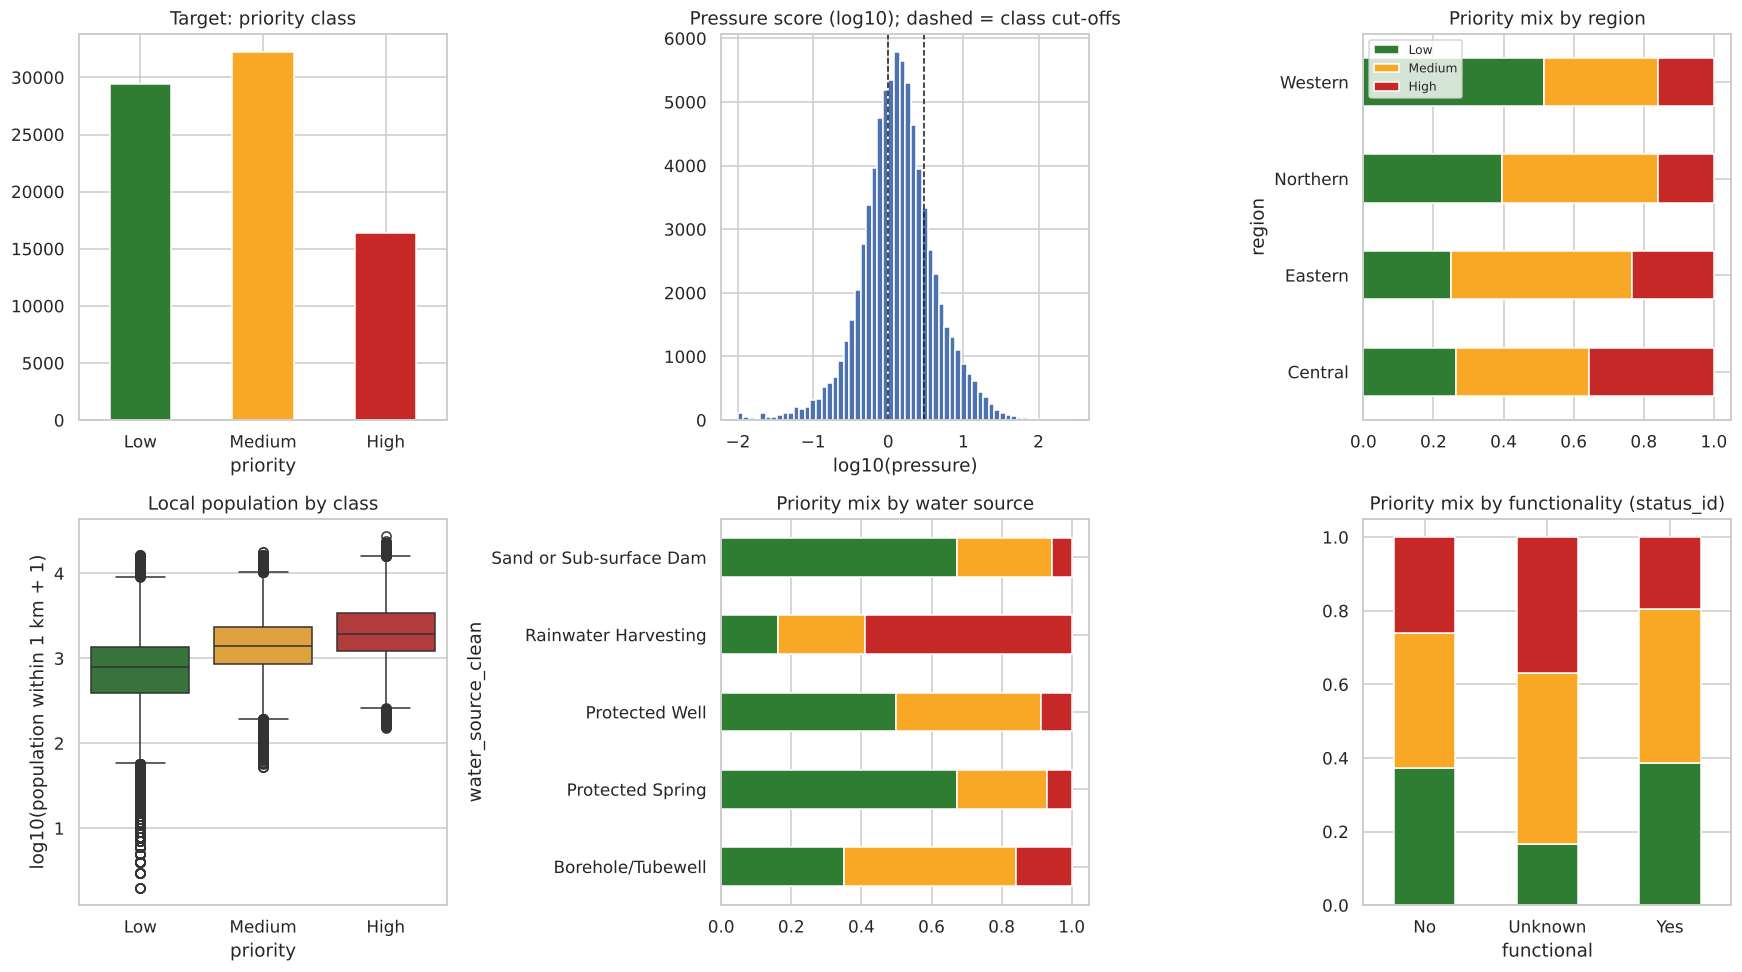

In [6]:
lab = df[df['priority'].notna()]
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
lab['priority'].value_counts().reindex(CLASSES).plot.bar(ax=ax[0, 0], color=[PAL[c] for c in CLASSES])
ax[0, 0].set_title('Target: priority class'); ax[0, 0].tick_params(axis='x', rotation=0)
ax[0, 1].hist(np.log10(lab['pressure_score'].clip(0.01, 300)), bins=60, color='#4C72B0')
for v in [1, 3]: ax[0, 1].axvline(np.log10(v), color='k', ls='--', lw=1)
ax[0, 1].set_title('Pressure score (log10); dashed = class cut-offs'); ax[0, 1].set_xlabel('log10(pressure)')
pd.crosstab(lab['region'], lab['priority'], normalize='index')[CLASSES].plot.barh(stacked=True, ax=ax[0, 2],
                                                                                  color=[PAL[c] for c in CLASSES])
ax[0, 2].set_title('Priority mix by region'); ax[0, 2].legend(fontsize=8)
sns.boxplot(data=lab, x='priority', y=np.log10(lab['local_population_1km'] + 1), order=CLASSES, ax=ax[1, 0],
            palette=PAL); ax[1, 0].set_ylabel('log10(population within 1 km + 1)'); ax[1, 0].set_title('Local population by class')
pd.crosstab(lab['water_source_clean'], lab['priority'], normalize='index')[CLASSES].plot.barh(stacked=True, ax=ax[1, 1],
                                                                                             color=[PAL[c] for c in CLASSES], legend=False)
ax[1, 1].set_title('Priority mix by water source')
pd.crosstab(lab['functional'], lab['priority'], normalize='index')[CLASSES].plot.bar(stacked=True, ax=ax[1, 2],
                                                                                    color=[PAL[c] for c in CLASSES], legend=False)
ax[1, 2].set_title('Priority mix by functionality (status_id)'); ax[1, 2].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.savefig(f'{FIG}/eda_overview.png', bbox_inches='tight'); plt.show()

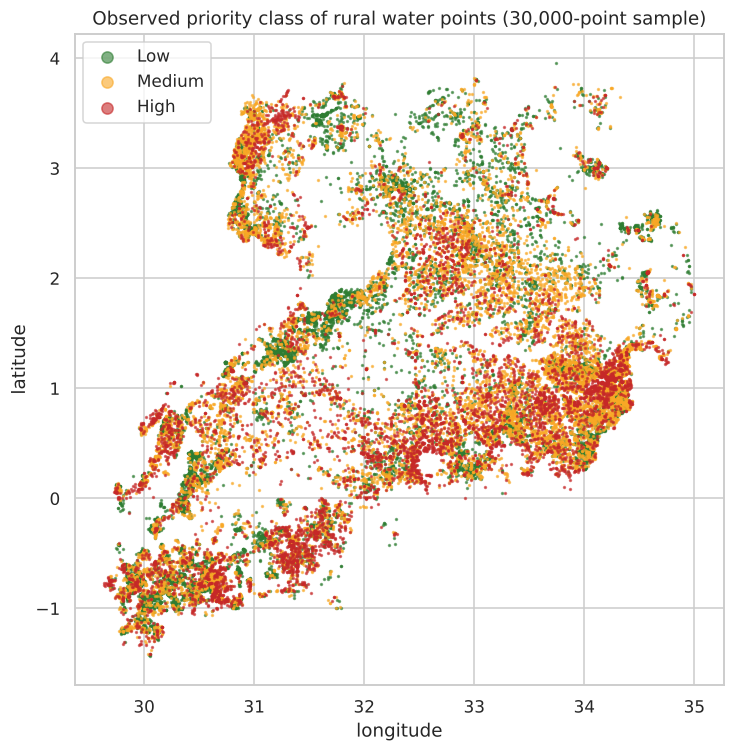

In [7]:
fig, ax = plt.subplots(figsize=(7, 7))
s = lab.sample(30000, random_state=RANDOM_STATE)
for c in CLASSES:
    t = s[s['priority'] == c]
    ax.scatter(t['lon_deg'], t['lat_deg'], s=1.5, c=PAL[c], label=c, alpha=.6)
ax.set_title('Observed priority class of rural water points (30,000-point sample)')
ax.set_xlabel('longitude'); ax.set_ylabel('latitude'); ax.legend(markerscale=6); ax.set_aspect('equal')
plt.tight_layout(); plt.savefig(f'{FIG}/map_observed_points.png', bbox_inches='tight', dpi=150); plt.show()

**What I learned from exploring the data.**

* After keeping only rural water points there are 96,271 records. 78,005 of them (81%) have a pressure score, and these are the rows I can train on. The other 19% mostly have no population figure.
* The classes are reasonably balanced: 38% Low, 41% Medium and 21% High. So a model that always guesses one class would score badly, which makes the baseline a fair comparison.
* The pressure score is very skewed (from almost 0 up to 787), which is why I used class cut-offs instead of predicting the raw number.
* Central and Eastern regions have the most overloaded water points; Western and Northern have more points within capacity.
* Rainwater harvesting tanks are very often *High*. This is because WPdx gives them a design capacity of only 50 people, compared with 250-300 for taps and hand pumps.
* About 70% of the records were collected in the 2010 national water point mapping, so the data describe the situation at that time more than today. I come back to this limitation in the report.

## 4. Spatial feature engineering

The proposal asks for spatial features describing water **access** and **demand** around each point. Using a haversine
`BallTree` over all rural water points I computed, for each point:
* the number of water points, and of **functional** water points, within 1 km and 3 km;
* the distance to the nearest other water point and to the nearest functional one.

These features use only locations and functionality, not the target.

In [8]:
R_EARTH = 6_371_000.0
coords = np.radians(df[['lat_deg', 'lon_deg']].values)
is_func = (df['functional'] == 'Yes').values
tree_all, tree_func = BallTree(coords, metric='haversine'), BallTree(coords[is_func], metric='haversine')
t0 = time.time()
for r in [1000, 3000]:
    df[f'n_wp_{r // 1000}km'] = tree_all.query_radius(coords, r / R_EARTH, count_only=True) - 1          # excluding itself
    df[f'n_func_{r // 1000}km'] = tree_func.query_radius(coords, r / R_EARTH, count_only=True) - is_func
d_all, _ = tree_all.query(coords, k=2)
df['dist_nearest_wp_m'] = d_all[:, 1] * R_EARTH
d_f, _ = tree_func.query(coords, k=2)
df['dist_nearest_func_m'] = np.where(is_func, d_f[:, 1], d_f[:, 0]) * R_EARTH
print(f'spatial features computed in {time.time() - t0:.1f}s')
df[['n_wp_1km', 'n_func_1km', 'n_wp_3km', 'n_func_3km', 'dist_nearest_wp_m', 'dist_nearest_func_m']].describe().T.round(1)

spatial features computed in 6.6s


,count,mean,std,min,25%,50%,75%,max
n_wp_1km,96271.0,11.9,25.3,0.0,2.0,5.0,13.0,352.0
n_func_1km,96271.0,9.7,21.0,0.0,1.0,4.0,10.0,267.0
n_wp_3km,96271.0,59.8,82.7,0.0,18.0,38.0,73.0,911.0
n_func_3km,96271.0,48.4,65.8,0.0,13.0,30.0,60.0,718.0
dist_nearest_wp_m,96271.0,436.6,516.2,0.8,130.3,299.4,565.9,15458.3
dist_nearest_func_m,96271.0,506.5,585.8,0.8,157.5,330.2,654.9,15658.1


## 5. Model development

**Inputs (22 variables).**
* *Demand:* population within 1 km (estimate provided in WPdx+).
* *The water point itself:* design capacity, water source, technology, facility type, functionality, age, management, payment.
* *Access:* distances to primary/secondary/tertiary roads, nearest town and city, cluster size.
* *Spatial (Section 4):* nearby water points and functional water points, nearest-neighbour distances.
* *Region:* Central, Eastern, Northern, Western.

**Honest evaluation.** Neighbouring water points share the same population, so a random train/test split would let the
model "see" the test area during training and overstate accuracy. Instead I split **by district**: 20% of districts are held
out completely as the test set, and cross-validation inside the training set is also grouped by district.

**Models.** A majority-class baseline, **logistic regression** (interpretable baseline), **random forest** and **XGBoost**
(as in the proposal). Classes are weighted so the smaller *High* class is not ignored. Hyper-parameters are tuned by
3-fold district-grouped CV on a 30,000-row sample of the training set, using **macro F1** (the average F1 of the three
classes), and the best settings are refitted on the full training set.

In [9]:
NUM = ['local_population_1km', 'usage_capacity', 'age_years', 'distance_to_primary_road', 'distance_to_secondary_road',
       'distance_to_tertiary_road', 'distance_to_town', 'distance_to_city', 'cluster_size',
       'n_wp_1km', 'n_func_1km', 'n_wp_3km', 'n_func_3km', 'dist_nearest_wp_m', 'dist_nearest_func_m']
CAT = ['water_source_clean', 'water_tech_category', 'facility_type', 'functional', 'management_clean', 'pay_clean', 'region']
FEATURES = NUM + CAT

data = df[df['priority'].notna()].reset_index(drop=True)
X, y = data[FEATURES], data['priority'].cat.codes.values          # 0 = Low, 1 = Medium, 2 = High
groups = data['district'].values

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
tr, te = next(gss.split(X, y, groups))
X_train, X_test, y_train, y_test = X.iloc[tr], X.iloc[te], y[tr], y[te]
g_train = groups[tr]
print(f'train: {len(tr):,} points in {len(set(groups[tr]))} districts | test: {len(te):,} points in {len(set(groups[te]))} districts')
print('class shares train', np.bincount(y_train) / len(y_train), 'test', np.bincount(y_test) / len(y_test))
RESULTS['split'] = {'train_n': int(len(tr)), 'test_n': int(len(te)), 'train_districts': int(len(set(groups[tr]))),
                    'test_districts': int(len(set(groups[te])))}

log1p = FunctionTransformer(np.log1p, feature_names_out='one-to-one')
def pre_linear():
    return ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('log', log1p), ('sc', StandardScaler())]), NUM),
        ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50, sparse_output=False), CAT)],
        verbose_feature_names_out=False)
def pre_tree():
    return ColumnTransformer([
        ('num', SimpleImputer(strategy='median'), NUM),
        ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50, sparse_output=False), CAT)],
        verbose_feature_names_out=False)

train: 64,091 points in 107 districts | test: 13,914 points in 27 districts
class shares train [0.37187749 0.41111857 0.21700395] test [0.39916631 0.42144603 0.17938767]


In [10]:
MODELS = {
    'Logistic Regression': (Pipeline([('pre', pre_linear()), ('clf', LogisticRegression(max_iter=3000, class_weight='balanced'))]),
                            {'clf__C': [0.1, 1, 10]}),
    'Random Forest': (Pipeline([('pre', pre_tree()), ('clf', RandomForestClassifier(n_estimators=200, max_features='sqrt',
                                class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1))]),
                      {'clf__max_depth': [12, 20, None], 'clf__min_samples_leaf': [2, 10]}),
    'XGBoost': (Pipeline([('pre', pre_tree()), ('clf', XGBClassifier(n_estimators=400, subsample=0.8, colsample_bytree=0.8,
                          objective='multi:softprob', eval_metric='mlogloss', tree_method='hist',
                          random_state=RANDOM_STATE, n_jobs=2))]),
                {'clf__max_depth': [4, 6, 8], 'clf__learning_rate': [0.05, 0.1]}),
}
rng = np.random.default_rng(RANDOM_STATE)
sub = rng.choice(len(X_train), 30000, replace=False)
gkf3 = GroupKFold(n_splits=3)
best, cv_summary = {}, {}
for name, (pipe, grid) in MODELS.items():
    t0 = time.time()
    fit_params = {}
    if name == 'XGBoost':     # XGBoost has no class_weight option, so balanced sample weights are passed instead
        fit_params = {'clf__sample_weight': compute_sample_weight('balanced', y_train[sub])}
    gs = GridSearchCV(pipe, grid, scoring='f1_macro', cv=gkf3, n_jobs=1)
    gs.fit(X_train.iloc[sub], y_train[sub], groups=g_train[sub], **fit_params)
    i = gs.best_index_
    cv_summary[name] = {'cv_macro_f1': gs.cv_results_['mean_test_score'][i], 'cv_sd': gs.cv_results_['std_test_score'][i],
                        'best_params': {k.replace('clf__', ''): v for k, v in gs.best_params_.items()}}
    final = clone(gs.best_estimator_)
    if name == 'XGBoost':
        final.fit(X_train, y_train, clf__sample_weight=compute_sample_weight('balanced', y_train))
    else:
        final.fit(X_train, y_train)
    best[name] = final
    print(f"{name:20s} grouped-CV macro-F1 = {cv_summary[name]['cv_macro_f1']:.3f} ± {cv_summary[name]['cv_sd']:.3f}  "
          f"{cv_summary[name]['best_params']}  ({time.time() - t0:.0f}s)")
best['Baseline (majority class)'] = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
RESULTS['cv'] = {k: {'macro_f1': round(float(v['cv_macro_f1']), 3), 'sd': round(float(v['cv_sd']), 3),
                     'params': {a: (b.item() if hasattr(b, 'item') else b) for a, b in v['best_params'].items()}}
                 for k, v in cv_summary.items()}

Logistic Regression  grouped-CV macro-F1 = 0.835 ± 0.007  {'C': 1}  (7s)


Random Forest        grouped-CV macro-F1 = 0.796 ± 0.028  {'max_depth': 20, 'min_samples_leaf': 2}  (68s)


XGBoost              grouped-CV macro-F1 = 0.842 ± 0.002  {'learning_rate': 0.05, 'max_depth': 6}  (73s)


## 6. Model evaluation and comparison (held-out districts)

In [11]:
def evaluate(y_true, proba):
    pred = proba.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y_true, pred, labels=[0, 1, 2], zero_division=0)
    out = {'Accuracy': accuracy_score(y_true, pred),
           'Macro precision': p.mean(), 'Macro recall': r.mean(), 'Macro F1': f.mean(),
           'Weighted F1': f1_score(y_true, pred, average='weighted'),
           'High: precision': p[2], 'High: recall': r[2], 'High: F1': f[2]}
    try: out['ROC-AUC (ovr)'] = roc_auc_score(y_true, proba, multi_class='ovr')
    except ValueError: out['ROC-AUC (ovr)'] = np.nan
    return out

order = ['Baseline (majority class)', 'Logistic Regression', 'Random Forest', 'XGBoost']
test_proba = {n: best[n].predict_proba(X_test) for n in order}
test_table = pd.DataFrame({n: evaluate(y_test, test_proba[n]) for n in order}).T
display(test_table.round(3))
RESULTS['test'] = test_table.round(4).to_dict(orient='index')

,Accuracy,Macro precision,Macro recall,Macro F1,Weighted F1,High: precision,High: recall,High: F1,ROC-AUC (ovr)
Baseline (majority class),0.421,0.140,0.333,0.198,0.250,0.000,0.000,0.000,0.500
Logistic Regression,0.821,0.812,0.827,0.819,0.821,0.768,0.848,0.806,0.937
Random Forest,0.808,0.803,0.803,0.803,0.808,0.776,0.776,0.776,0.929
XGBoost,0.818,0.807,0.826,0.815,0.818,0.751,0.855,0.799,0.939


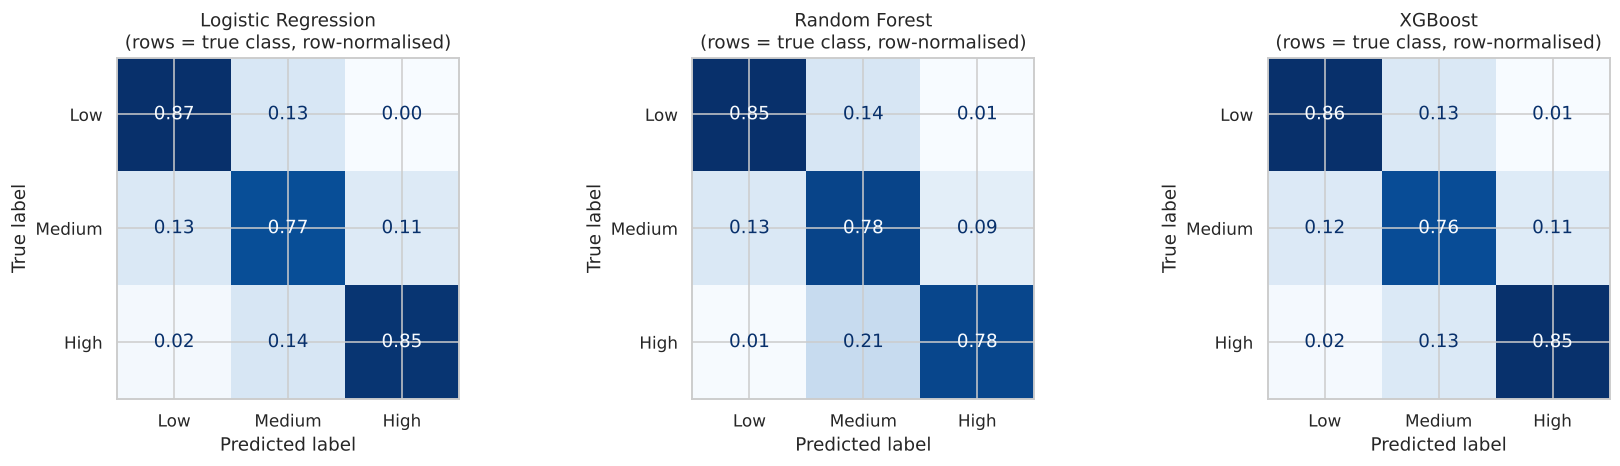

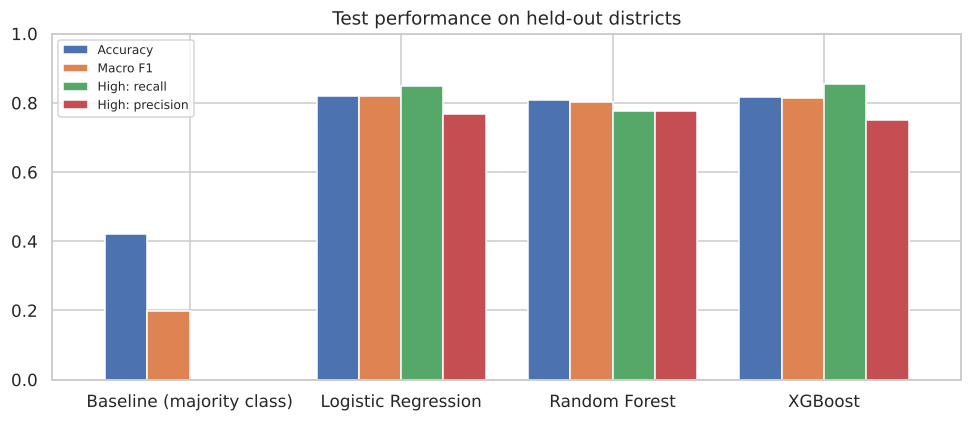

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for a, n in zip(ax, order[1:]):
    ConfusionMatrixDisplay.from_predictions(y_test, test_proba[n].argmax(1), display_labels=CLASSES, normalize='true',
                                            values_format='.2f', ax=a, colorbar=False, cmap='Blues')
    a.set_title(f'{n}\n(rows = true class, row-normalised)')
plt.tight_layout(); plt.savefig(f'{FIG}/confusion_matrices.png', bbox_inches='tight', dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
test_table.loc[order, ['Accuracy', 'Macro F1', 'High: recall', 'High: precision']].plot.bar(ax=ax, width=.8)
ax.set_ylim(0, 1); ax.set_title('Test performance on held-out districts'); ax.tick_params(axis='x', rotation=0)
ax.legend(fontsize=8, loc='upper left'); plt.tight_layout(); plt.savefig(f'{FIG}/model_comparison.png', bbox_inches='tight'); plt.show()

**Selection rule (fixed before looking at the test set).** Choose the model with the highest grouped-CV macro F1. If
logistic regression is within 0.01 of the best, prefer it because it is simpler to explain.

In [13]:
cvf = pd.Series({k: v['cv_macro_f1'] for k, v in cv_summary.items()})
top = cvf.idxmax()
SELECTED = 'Logistic Regression' if cvf[top] - cvf['Logistic Regression'] <= 0.01 else top
sel = best[SELECTED]
print('Selected model:', SELECTED)
print(classification_report(y_test, test_proba[SELECTED].argmax(1), target_names=CLASSES, digits=3))
RESULTS['selected'] = SELECTED
cm = confusion_matrix(y_test, test_proba[SELECTED].argmax(1), labels=[0, 1, 2])
RESULTS['selected_confusion'] = cm.tolist()
RESULTS['high_missed_as_low'] = round(float(cm[2, 0] / cm[2].sum()), 3)
RESULTS['low_flagged_high'] = round(float(cm[0, 2] / cm[0].sum()), 3)

Selected model: Logistic Regression
              precision    recall  f1-score   support

         Low      0.861     0.867     0.864      5554
      Medium      0.807     0.766     0.786      5864
        High      0.768     0.848     0.806      2496

    accuracy                          0.821     13914
   macro avg      0.812     0.827     0.819     13914
weighted avg      0.822     0.821     0.821     13914



**What the evaluation shows.**

* All three models are far better than the baseline (macro F1 about 0.80-0.82 versus 0.20), on districts they never saw during training.
* XGBoost had the best cross-validation score (0.842), but logistic regression was only 0.007 behind (0.835). Under my rule, I chose **logistic regression**. On the test districts it actually did slightly better than XGBoost (macro F1 0.819 vs 0.815), so the simpler model does not cost anything here.
* For planning, the most important class is *High*. Logistic regression finds 85% of the high-priority water points (recall 0.848), and when it says *High* it is right 77% of the time (precision 0.768).
* The mistakes are almost all between neighbouring classes (Low vs Medium, Medium vs High). Only 1.6% of truly *High* points were called *Low*, and no *Low* point was called *High*. That matters, because these are the most costly errors for a planner.
* Random forest was the weakest model and the least stable across folds (±0.028), probably because it overfits to district-specific patterns.

## 7. Interpretation of results

### 7.1 Which factors drive the priority class? (SHAP)
SHAP gives each feature's contribution to the predicted score of the **High** class for each water point. Positive
values push a point towards *High priority*. Values are computed for 3,000 test points.

,mean |SHAP| (High class)
local_population_1km,3.708
n_func_1km,2.220
usage_capacity,2.038
n_func_3km,0.893
water_tech_category,0.644
dist_nearest_func_m,0.557
region,0.487
water_source_clean,0.434
management_clean,0.289
n_wp_3km,0.288


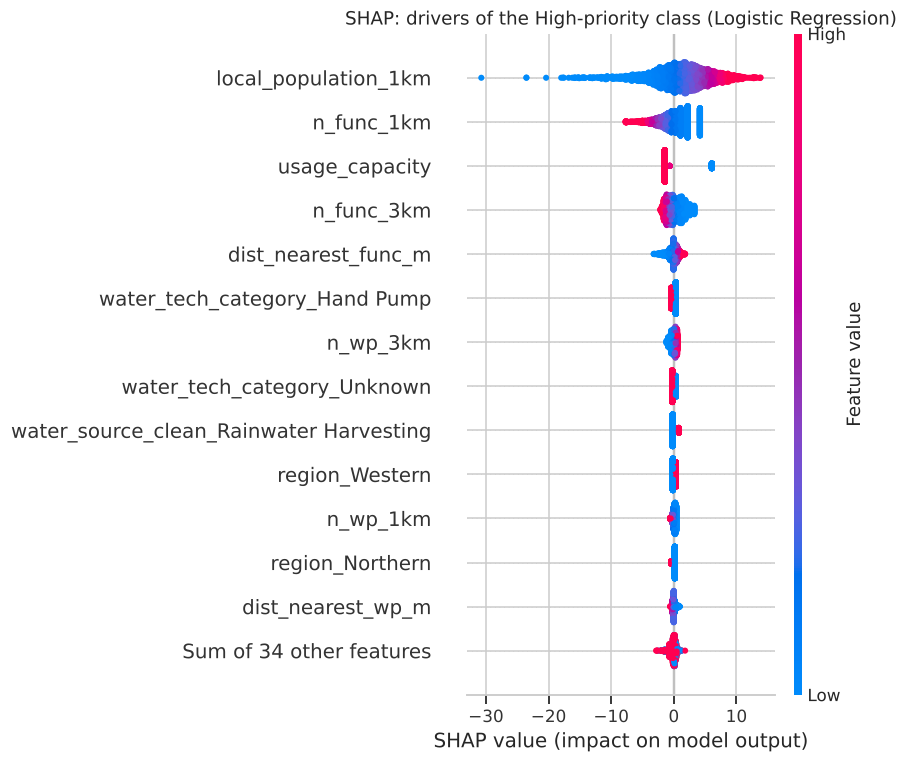

In [14]:
pre, clf = sel.named_steps['pre'], sel.named_steps['clf']
fnames = list(pre.get_feature_names_out())
idx = np.random.default_rng(0).choice(len(X_test), 3000, replace=False)
Xs = pd.DataFrame(pre.transform(X_test.iloc[idx]), columns=fnames)
if isinstance(clf, LogisticRegression):
    bg = pd.DataFrame(pre.transform(X_train.sample(1000, random_state=0)), columns=fnames)
    sv = shap.LinearExplainer(clf, shap.maskers.Independent(bg, max_samples=1000))(Xs)
else:
    sv = shap.TreeExplainer(clf)(Xs)
sv_high = sv[:, :, 2] if sv.values.ndim == 3 else sv
if isinstance(clf, LogisticRegression):      # show original units on the colour scale
    disp = Xs.copy()
    for c in NUM: disp[c] = X_test.iloc[idx][c].values
    sv_high.data = disp.values
# aggregate one-hot columns back to the original 22 variables
def base(n):
    for c in CAT:
        if n.startswith(c + '_'): return c
    return n
shap_df = pd.DataFrame(sv_high.values, columns=fnames)
imp = shap_df.abs().T.groupby(base).sum().T.mean().sort_values(ascending=False)
display(imp.round(3).to_frame('mean |SHAP| (High class)'))
RESULTS['shap_importance'] = imp.round(4).to_dict()

plt.figure()
shap.plots.beeswarm(sv_high, max_display=14, show=False)
plt.title(f'SHAP: drivers of the High-priority class ({SELECTED})'); plt.tight_layout()
plt.savefig(f'{FIG}/shap_beeswarm_high.png', bbox_inches='tight', dpi=150); plt.show()

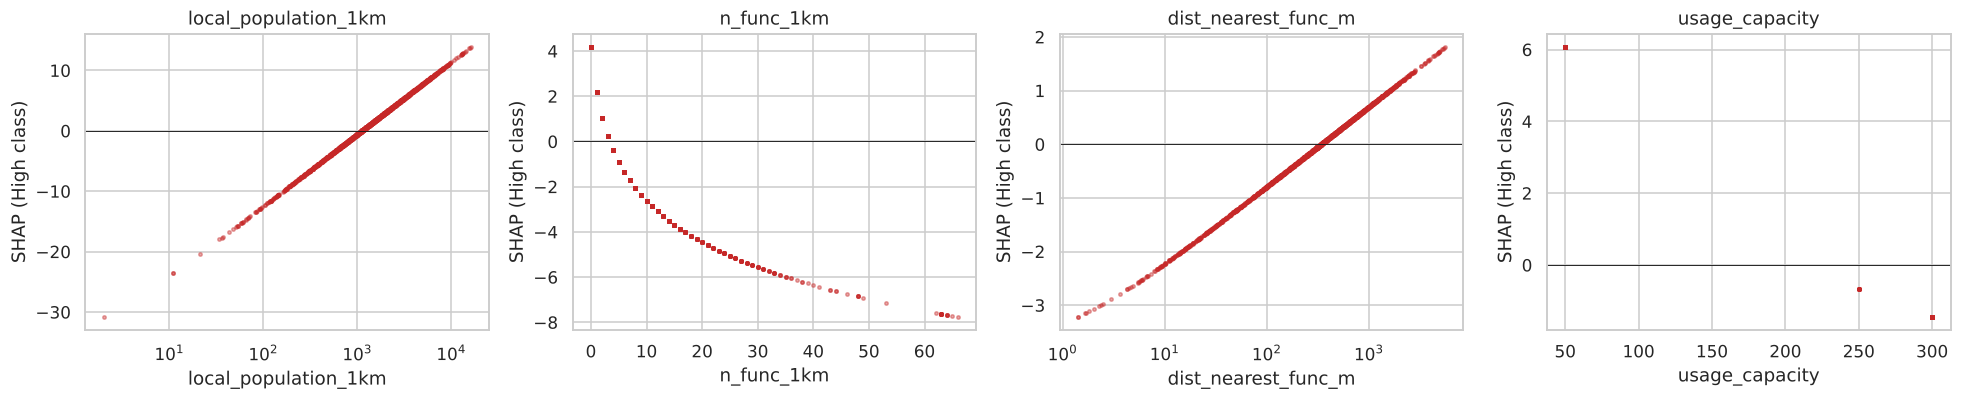

In [15]:
raw = X_test.iloc[idx].reset_index(drop=True)
show = [f for f in ['local_population_1km', 'n_func_1km', 'dist_nearest_func_m', 'usage_capacity'] if f in fnames]
fig, ax = plt.subplots(1, len(show), figsize=(4.5 * len(show), 3.8))
for a, f in zip(ax, show):
    xv = raw[f]
    a.scatter(xv, shap_df[f], s=5, alpha=.4, c='#C62828')
    if f in ['local_population_1km', 'dist_nearest_func_m']: a.set_xscale('log')
    a.axhline(0, color='k', lw=.6); a.set_xlabel(f); a.set_ylabel('SHAP (High class)'); a.set_title(f)
plt.tight_layout(); plt.savefig(f'{FIG}/shap_dependence.png', bbox_inches='tight', dpi=150); plt.show()

### 7.2 How much does population data matter? (ablation)
Population is the only demand input. To see how much the model depends on it, I retrained the selected model
**without** `local_population_1km`, keeping all water-point and spatial features.

In [16]:
NUM2 = [c for c in NUM if c != 'local_population_1km']
pre2 = ColumnTransformer([('num', SimpleImputer(strategy='median'), NUM2),
                          ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50, sparse_output=False), CAT)])
if isinstance(clf, LogisticRegression):
    pre2 = ColumnTransformer([('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('log', log1p), ('sc', StandardScaler())]), NUM2),
                              ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50, sparse_output=False), CAT)])
m2 = Pipeline([('pre', pre2), ('clf', clone(clf))])
fp = {'clf__sample_weight': compute_sample_weight('balanced', y_train)} if isinstance(clf, XGBClassifier) else {}
m2.fit(X_train.drop(columns='local_population_1km'), y_train, **fp)
abl = pd.DataFrame({'with population': evaluate(y_test, test_proba[SELECTED]),
                    'without population': evaluate(y_test, m2.predict_proba(X_test.drop(columns='local_population_1km')))}).T
display(abl[['Accuracy', 'Macro F1', 'High: recall', 'High: precision', 'ROC-AUC (ovr)']].round(3))
RESULTS['ablation_no_population'] = abl.round(4).to_dict(orient='index')

,Accuracy,Macro F1,High: recall,High: precision,ROC-AUC (ovr)
with population,0.821,0.819,0.848,0.768,0.937
without population,0.574,0.572,0.633,0.541,0.760


### 7.3 Does the model work equally well in every region?

In [17]:
reg = data['region'].values[te]
pred_sel = test_proba[SELECTED].argmax(1)
rows = {}
for r in sorted(set(reg)):
    m = reg == r
    p, rc, f, _ = precision_recall_fscore_support(y_test[m], pred_sel[m], labels=[0, 1, 2], zero_division=0)
    rows[r] = {'n test points': int(m.sum()), 'share High (true)': (y_test[m] == 2).mean(),
               'Accuracy': accuracy_score(y_test[m], pred_sel[m]), 'Macro F1': f.mean(), 'High: recall': rc[2]}
by_region = pd.DataFrame(rows).T
display(by_region.round(3))
RESULTS['by_region'] = by_region.round(3).to_dict(orient='index')

,n test points,share High (true),Accuracy,Macro F1,High: recall
Central,2327.0,0.294,0.828,0.832,0.934
Eastern,4767.0,0.180,0.807,0.797,0.781
Northern,961.0,0.214,0.814,0.816,0.883
Western,5859.0,0.127,0.831,0.812,0.835


**What drives the priority class.**

* **Population within 1 km** is by far the strongest factor: more people nearby pushes a water point towards *High*.
* The second is the **number of working water points within 1 km**: the more functional water points close by, the more the people are shared out, and the lower the priority. The distance to the nearest functional point works the same way: further away means higher priority.
* **Design capacity** is third. Small-capacity sources (rainwater tanks, 50 people) become overloaded very quickly.
* Distance to roads and towns, age of the water point and payment method hardly matter once population and nearby water points are known.

This matches common sense and the logic of the problem: a place needs a new water point when many people depend on few working water points. It also shows the model did not learn something strange.

**Population data is essential.** Without the population feature, macro F1 falls from 0.82 to 0.57 and ROC-AUC from 0.94 to 0.76. Infrastructure data alone is not enough to judge need, so good population data (e.g. WorldPop) is a requirement for this kind of planning tool.

**Regions.** Accuracy is similar in all four regions (0.81-0.83). Recall for *High* is lowest in the Eastern region (0.78) and highest in Central (0.93), so planners in the East should treat a *Medium* result with a bit more caution.

## 8. Priority map of sub-counties

To produce the map in the proposal (objective 4) without letting the model grade its own homework, every labelled water
point is scored by a model trained on **other districts only** (5-fold district-grouped cross-validation of the selected
model). Each point gets a priority score = P(Medium) × 1 + P(High) × 2 (0 = surely Low, 2 = surely High). Sub-counties are
then classified by their **average** score: Low < 0.67 ≤ Medium < 1.33 ≤ High. Sub-counties with fewer than 10 scored
water points are left out.

In [18]:
t0 = time.time()
fp = {'clf__sample_weight': compute_sample_weight('balanced', y)} if isinstance(clf, XGBClassifier) else {}
oof = cross_val_predict(clone(sel), X, y, groups=groups, cv=GroupKFold(n_splits=5), method='predict_proba', params=fp)
print(f'out-of-district predictions in {time.time() - t0:.0f}s; macro F1 =', round(f1_score(y, oof.argmax(1), average='macro'), 3))
data['pred_score'] = oof[:, 1] + 2 * oof[:, 2]
data['obs_score'] = y                                           # 0/1/2 observed class
sc = (data.groupby('subcounty')
          .agg(district=('district', 'first'), region=('region', 'first'), n_points=('pred_score', 'size'),
               lat=('lat_deg', 'mean'), lon=('lon_deg', 'mean'), pred_score=('pred_score', 'mean'),
               obs_score=('obs_score', 'mean'), pop_1km_median=('local_population_1km', 'median'),
               share_functional=('functional', lambda s: (s == 'Yes').mean())))
sc = sc[sc['n_points'] >= 10].copy()
sc['priority'] = pd.cut(sc['pred_score'], [-np.inf, 0.67, 1.33, np.inf], labels=CLASSES)
rho = spearmanr(sc['pred_score'], sc['obs_score'])[0]
print(f'{len(sc)} sub-counties mapped; Spearman correlation predicted vs observed sub-county score = {rho:.2f}')
print(sc['priority'].value_counts().reindex(CLASSES))
sc.sort_values('pred_score', ascending=False).round(3).to_csv(f'{OUTD}/subcounty_priority.csv')
RESULTS['oof_macro_f1'] = round(float(f1_score(y, oof.argmax(1), average='macro')), 3)
RESULTS['map'] = {'n_subcounties': int(len(sc)), 'spearman_pred_vs_obs': round(float(rho), 3),
                  'counts': sc['priority'].value_counts().reindex(CLASSES).astype(int).to_dict()}
top15 = sc.sort_values('pred_score', ascending=False).head(15)[['district', 'region', 'n_points', 'pop_1km_median',
                                                                   'share_functional', 'pred_score', 'obs_score']]
display(top15.round(2))
RESULTS['top15'] = top15.round(3).reset_index().to_dict(orient='records')
RESULTS['high_by_region'] = sc[sc['priority'] == 'High'].groupby('region').size().to_dict()

out-of-district predictions in 8s; macro F1 = 0.834
1252 sub-counties mapped; Spearman correlation predicted vs observed sub-county score = 0.92
priority
Low       285
Medium    707
High      260
Name: count, dtype: int64


,district,region,n_points,pop_1km_median,share_functional,pred_score,obs_score
subcounty,,,,,,,
Wakiso / Ndejje Division,Wakiso,Central,13,15154.0,1.00,2.00,2.00
Bugweri / Busembatia Town Council,Bugweri,Eastern,10,12258.5,1.00,1.99,2.00
Tororo / Malaba Town Council,Tororo,Eastern,10,10229.0,1.00,1.98,2.00
Mbale / Bukasakya,Mbale,Eastern,33,10253.0,0.30,1.98,1.97
Mbale / Nakaloke Town Council,Mbale,Eastern,40,9779.0,0.35,1.97,1.95
Yumbe / Yumbe Town Council,Yumbe,Northern,15,6742.0,1.00,1.96,1.93
Mbale / Nakaloke,Mbale,Eastern,21,5780.0,0.19,1.95,1.95
Bugiri / Western Division,Bugiri,Eastern,11,19188.0,1.00,1.94,2.00
Buikwe / Njeru Division,Buikwe,Central,18,7184.5,0.89,1.90,1.89


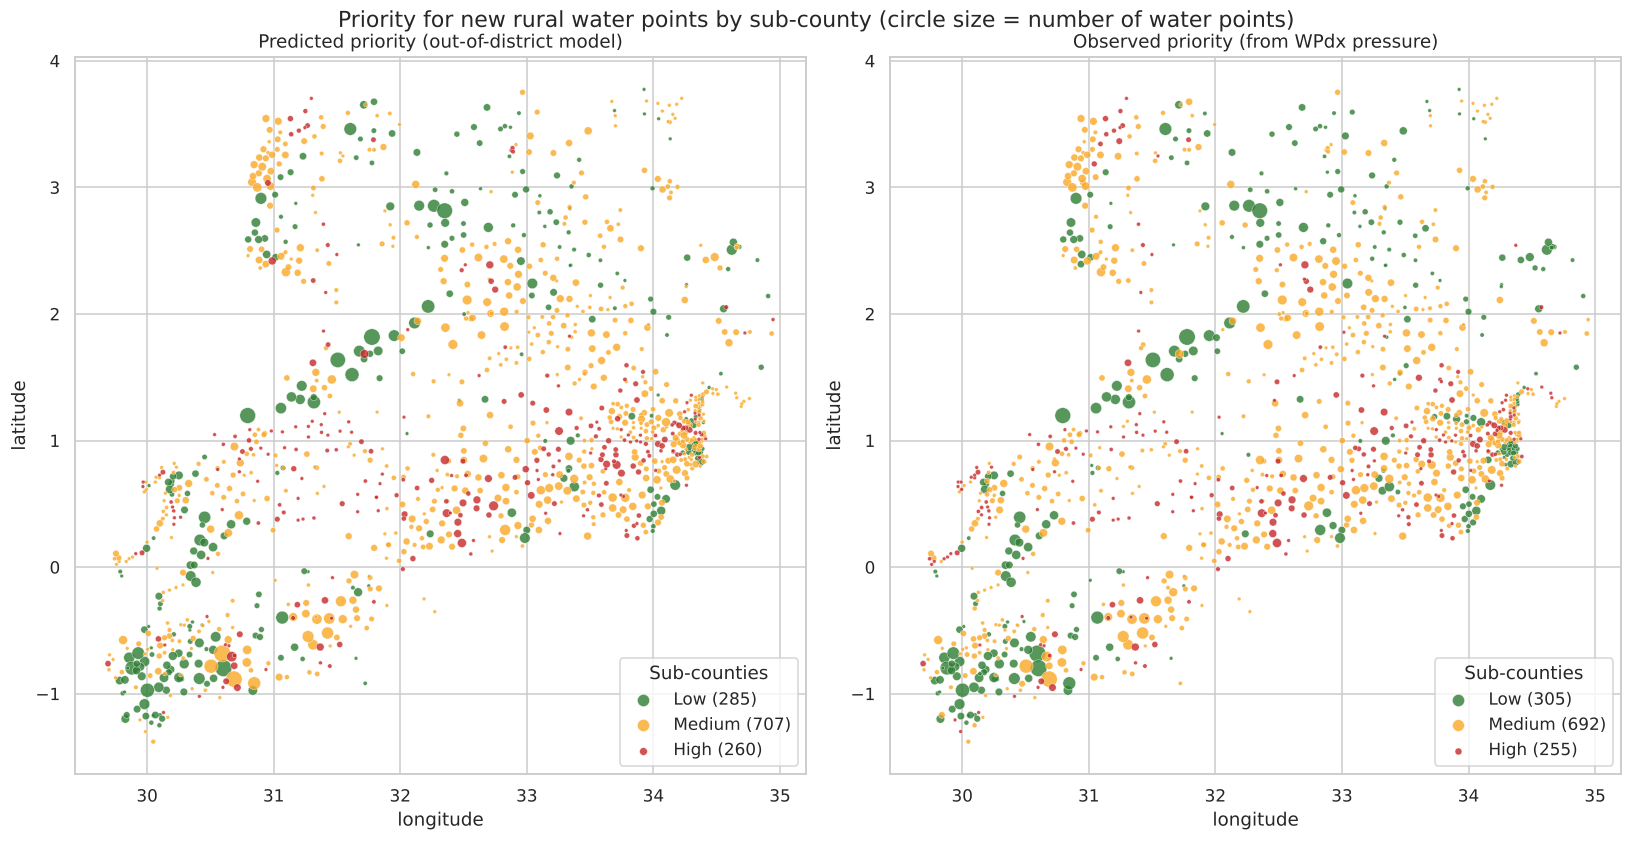

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(15, 7.5))
for a, col, title in [(ax[0], 'priority', 'Predicted priority (out-of-district model)'),
                      (ax[1], None, 'Observed priority (from WPdx pressure)')]:
    if col:
        cls = sc['priority']
    else:
        cls = pd.cut(sc['obs_score'], [-np.inf, 0.67, 1.33, np.inf], labels=CLASSES)
    for c in CLASSES:
        t = sc[cls == c]
        a.scatter(t['lon'], t['lat'], s=np.clip(t['n_points'] / 4, 6, 120), c=PAL[c], label=f'{c} ({len(t)})',
                  alpha=.8, edgecolor='white', linewidth=.3)
    a.set_title(title); a.set_xlabel('longitude'); a.set_ylabel('latitude'); a.set_aspect('equal'); a.legend(title='Sub-counties')
plt.suptitle('Priority for new rural water points by sub-county (circle size = number of water points)')
plt.tight_layout(); plt.savefig(f'{FIG}/priority_map_subcounties.png', bbox_inches='tight', dpi=150); plt.show()

In [20]:
# Interactive map (open outputs/priority_map.html in a browser)
fmap = folium.Map(location=[1.4, 32.4], zoom_start=7, tiles='cartodbpositron')
for name, r in sc.iterrows():
    folium.CircleMarker([r['lat'], r['lon']], radius=float(np.clip(np.sqrt(r['n_points']) / 2, 3, 14)),
                        color=PAL[r['priority']], fill=True, fill_opacity=.75, weight=1,
                        popup=folium.Popup(f"<b>{name}</b><br>Region: {r['region']}<br>Priority: <b>{r['priority']}</b>"
                                           f"<br>Score: {r['pred_score']:.2f} (0=Low, 2=High)<br>Water points: {r['n_points']}"
                                           f"<br>Median pop. within 1 km: {r['pop_1km_median']:.0f}"
                                           f"<br>Functional: {r['share_functional']:.0%}", max_width=260)).add_to(fmap)
fmap.save(f'{OUTD}/priority_map.html')
print('saved', f'{OUTD}/priority_map.html')

saved outputs/priority_map.html


**Reading the map.** The predicted map (left) looks almost the same as the map from the observed pressure scores (right): across 1,252 sub-counties, the rank correlation is 0.92, even though every district was scored by a model that never saw it. 260 sub-counties come out as *High* priority. They are concentrated in Central (32% of its sub-counties) and Eastern (25%) regions, especially around Wakiso, Mbale, Namutumba, Butaleja, Kamuli and Kakumiro. Northern region has the fewest (9%). About a third of the *High* sub-counties are town councils or divisions, i.e. fast-growing small towns that WPdx still labels as rural. The full ranked list is saved in `outputs/subcounty_priority.csv`, and `outputs/priority_map.html` is an interactive version of the map.

## 9. Summary of results

In [21]:
def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.bool_): return bool(o)
    return o
with open(f'{OUTD}/results.json', 'w') as f:
    json.dump(_clean(RESULTS), f, indent=1)
print(json.dumps(_clean({k: RESULTS[k] for k in ['selected', 'cv', 'map']}), indent=1))

{
 "selected": "Logistic Regression",
 "cv": {
  "Logistic Regression": {
   "macro_f1": 0.835,
   "sd": 0.007,
   "params": {
    "C": 1
   }
  },
  "Random Forest": {
   "macro_f1": 0.796,
   "sd": 0.028,
   "params": {
    "max_depth": 20,
    "min_samples_leaf": 2
   }
  },
  "XGBoost": {
   "macro_f1": 0.842,
   "sd": 0.002,
   "params": {
    "learning_rate": 0.05,
    "max_depth": 6
   }
  }
 },
 "map": {
  "n_subcounties": 1252,
  "spearman_pred_vs_obs": 0.92,
  "counts": {
   "Low": 285,
   "Medium": 707,
   "High": 260
  }
 }
}


**Conclusion.** The model answers the project question. Using population, the type and capacity of each water point, and the number of working water points nearby, it can sort rural water points into low, medium and high priority with about 82% accuracy on districts it has never seen, and it rarely makes the costly Low/High mix-up. The results are easy to explain to a planner: priority is high where many people depend on few working water points. The main limitations are that most records are from 2010, the target comes from WPdx's own estimate of people served rather than a field survey, and the model ranks *existing* water points rather than empty locations. The model should therefore support WaterAid's planning (e.g. which sub-counties to survey first), not replace field visits.